In [14]:
import pandas as pd
df = pd.read_csv("../data/health_fitness_dataset.csv")
drop_cols = ["activity_type", "intensity", "stress_level", "hours_sleep","hydration_level","blood_pressure_systolic","blood_pressure_diastolic","health_condition","smoking_status","fitness_level"]
df = df.drop(columns=drop_cols, errors="ignore")

df.head()


,participant_id,date,age,gender,height_cm,weight_kg,duration_minutes,calories_burned,avg_heart_rate,daily_steps,bmi,resting_heart_rate
0,1,2024-01-01,56,F,165.3,53.7,41,3.3,103,7128,19.6,69.5
1,1,2024-01-04,56,F,165.3,53.9,28,2.9,102,7925,19.6,69.5
2,1,2024-01-05,56,F,165.3,54.2,21,2.6,126,7557,19.6,69.5
3,1,2024-01-07,56,F,165.3,54.4,99,10.7,141,11120,19.6,69.5
4,1,2024-01-09,56,F,165.3,54.7,100,12.7,112,5406,19.6,69.5


In [15]:
# 📘 2️⃣ 컬럼명 정리 및 결측값 처리
# 모든 컬럼명을 소문자로 변환하고 공백 제거
df.columns = df.columns.str.strip().str.lower()

# 불필요한 컬럼이 있으면 제거 (예: 텍스트 라벨만 있는 stress_level 등)
# df = df.drop(columns=["stress_level"], errors="ignore")

# 결측값이 얼마나 있는지 확인
df.isnull().sum().head(10)


participant_id      0
date                0
age                 0
gender              0
height_cm           0
weight_kg           0
duration_minutes    0
calories_burned     0
avg_heart_rate      0
daily_steps         0
dtype: int64

In [16]:
# 📘 3️⃣ 신체정보 기반 BMI 계산
df["bmi"] = df["weight_kg"] / ((df["height_cm"] / 100) ** 2)

# 데이터 타입과 요약統計
df.describe().T.head(10)


,count,mean,std,min,25%,50%,75%,max
participant_id,687701.0,1499.781828,865.997215,1.000000,749.000000,1499.000000,2249.000000,3000.000000
age,687701.0,41.658602,13.581770,18.000000,30.000000,42.000000,53.000000,64.000000
height_cm,687701.0,168.587699,9.140811,145.000000,161.700000,168.200000,175.300000,198.500000
weight_kg,687701.0,94.921981,22.461801,45.300000,78.200000,94.600000,110.500000,188.400000
duration_minutes,687701.0,70.011671,29.147251,20.000000,45.000000,70.000000,95.000000,120.000000
calories_burned,687701.0,15.381302,9.985552,0.800000,7.800000,13.000000,20.700000,92.000000
avg_heart_rate,687701.0,131.454165,17.814744,82.000000,118.000000,130.000000,144.000000,206.000000
daily_steps,687701.0,8628.370918,2054.756608,-419.000000,7203.000000,8607.000000,10027.000000,17241.000000
bmi,687701.0,33.289632,6.979436,14.246705,27.916389,33.281395,38.595517,55.890185
resting_heart_rate,687701.0,70.010547,5.074563,51.100000,66.500000,70.000000,73.500000,87.100000


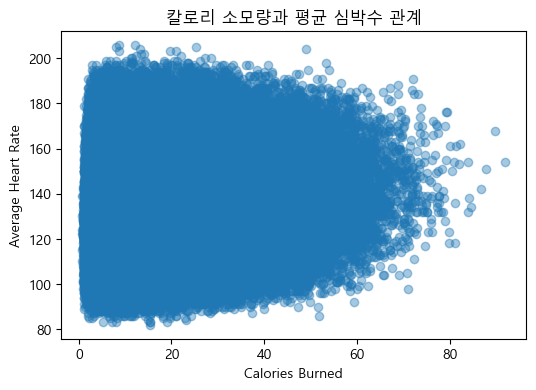

In [17]:
# 📘 4️⃣ matplotlib을 이용한 시각화
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지


plt.figure(figsize=(6,4))
plt.scatter(df["calories_burned"], df["avg_heart_rate"], alpha=0.4)
plt.xlabel("Calories Burned")
plt.ylabel("Average Heart Rate")
plt.title("칼로리 소모량과 평균 심박수 관계")
plt.show()


In [7]:
# 📘 5️⃣ 날짜별 정렬 및 14일 이동평균 피처 생성
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["participant_id", "date"])

# 사용자별 이동평균
df["avg_steps_14"] = df.groupby("participant_id")["daily_steps"].rolling(14).mean().reset_index(0, drop=True)
df["avg_hr_14"] = df.groupby("participant_id")["avg_heart_rate"].rolling(14).mean().reset_index(0, drop=True)

# 다음날 걸음수를 타깃으로 지정
df["next_steps"] = df.groupby("participant_id")["daily_steps"].shift(-1)

# 결측 제거
train_df = df.dropna(subset=["avg_steps_14", "avg_hr_14", "next_steps"])
print("학습용 데이터 크기:", train_df.shape)
train_df.head(3)


학습용 데이터 크기: (645701, 25)


,participant_id,date,age,gender,height_cm,weight_kg,activity_type,duration_minutes,intensity,calories_burned,...,bmi,resting_heart_rate,blood_pressure_systolic,blood_pressure_diastolic,health_condition,smoking_status,fitness_level,avg_steps_14,avg_hr_14,next_steps
13,1,2024-01-22,56,F,165.3,57.0,HIIT,38,Medium,8.6,...,20.860713,69.5,110.7,72.9,NaN,Never,1.16,8578.500000,119.142857,9032.0
14,1,2024-01-25,56,F,165.3,57.3,Weight Training,99,High,13.2,...,20.970506,69.5,110.7,72.9,NaN,Never,1.30,8714.500000,122.285714,7558.0
15,1,2024-01-28,56,F,165.3,57.5,Running,33,Medium,6.2,...,21.043702,69.5,110.7,72.9,NaN,Never,1.34,8688.285714,124.214286,9368.0


In [8]:
# 📘 6️⃣ LightGBM을 이용한 회귀 모델 학습
import lightgbm as lgb

# 입력(X)과 출력(y) 지정
X = train_df[["avg_steps_14", "avg_hr_14", "bmi", "calories_burned", "duration_minutes"]]
y = train_df["next_steps"]

# 데이터셋 준비
train_data = lgb.Dataset(X, label=y)

# 하이퍼파라미터 설정
params = {
    "objective": "regression",
    "metric": "rmse",
    "learning_rate": 0.05,
    "num_leaves": 31
}

# 모델 학습
model = lgb.train(params, train_data, num_boost_round=200)
print("✅ 모델 학습 완료")


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002260 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1122
[LightGBM] [Info] Number of data points in the train set: 645701, number of used features: 5
[LightGBM] [Info] Start training from score 8622.773710
✅ 모델 학습 완료


In [9]:
# 📘 7️⃣ 모델 저장 및 예측 테스트
import os
os.makedirs("../models", exist_ok=True)
model.save_model("../models/fitlife_steps_model.txt")
print("✅ 모델 저장 완료: ../models/fitlife_steps_model.txt")

# 테스트 입력 예시
sample = X.iloc[0:1]
pred = model.predict(sample)[0]
print("예측 결과 (다음날 예상 걸음수):", round(pred, 1))


✅ 모델 저장 완료: ../models/fitlife_steps_model.txt
예측 결과 (다음날 예상 걸음수): 9319.7


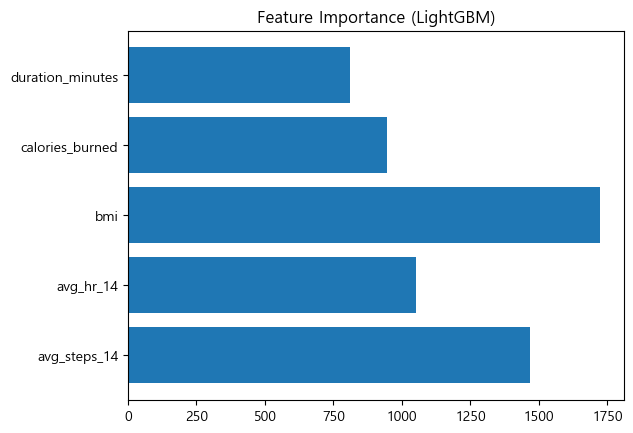

In [11]:
# 📘 8️⃣ 피처 중요도 시각화
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지


importance = model.feature_importance()
features = X.columns
plt.barh(features, importance)
plt.title("Feature Importance (LightGBM)")
plt.show()
